# 02 — Quantum Chat: arsitektur, framing, biaya dan eksperimen

Notebook ini menelusuri pesan UTF-8 melalui engine aplikasi, membedakan
penerimaan dari konfirmasi ACK, serta menjalankan uji ideal dan berisik.
Seluruh angka tabel dihitung saat notebook dieksekusi.


In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as metadata
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists() and (p/'densechat').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cirq, qsimcirq
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from scripts.notebook_support import style, save, COLORS
style()
SEED = 20261106
print('Python:', platform.python_version(), '| seed:', SEED)
print({name: metadata.version(name) for name in ['cirq-core', 'qsimcirq', 'numpy', 'matplotlib']})


Python: 3.12.16 | seed: 20261106
{'cirq-core': '1.7.0', 'qsimcirq': '0.22.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


## 1. Dua lapisan yang berbeda

Diagram menggambarkan alur logis dalam backend tepercaya. TCP lokal antara
terminal dan backend adalah komunikasi **klasik**, termasuk teks input.
Transfer A pada circuit adalah model quantum. Keduanya tidak boleh dicampur
untuk mengklaim payload fisik tanpa saluran atau biaya komunikasi nol.


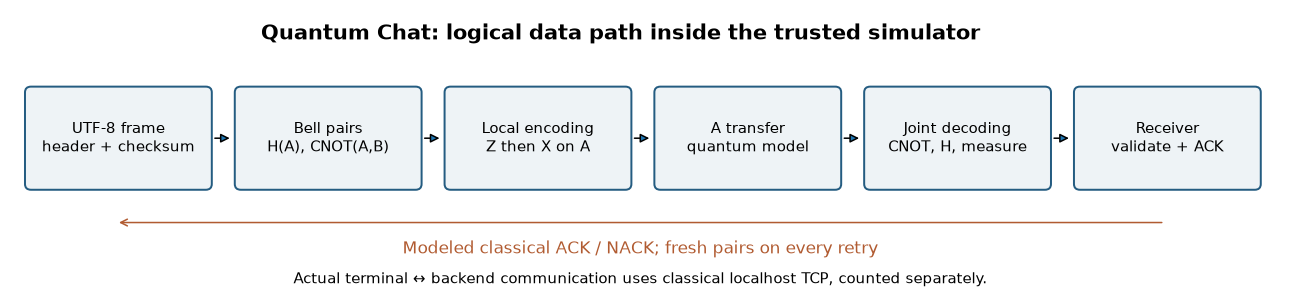

In [2]:
from scripts.notebook_support import architecture
fig = architecture()
save(fig, 'quantum_chat_architecture')
display(fig); plt.close(fig)


## 2. Protokol byte dan roundtrip dua arah

Frame = header 15 byte + payload UTF-8 + SHA-256 32 byte. Header memuat
sequence dan panjang. Setiap dua bit memakai Bell pair baru. Endpoint
penerima hanya menerima byte hasil pengukuran, lalu memvalidasi frame.
Checksum tanpa kunci mendeteksi kerusakan tak sengaja, bukan autentikasi.


In [3]:
from densechat.session import ChatSession
from densechat.protocol import HEADER, ACK_SIZE, encode_message
session = ChatSession(seed=SEED)
for name in ('Bumi', 'Mars'):
    session.add_endpoint(name)
messages = [('Bumi','Mars','Hai! Apa kabarmu hari ini'), ('Mars','Bumi','Diterima, Bumi! 🌏'), ('Bumi','Mars','')]
delivery_rows = []
for sender, recipient, text in messages:
    result = session.send(sender, recipient, text)
    assert result.confirmed and result.received_text == text
    delivery_rows.append({'sender': sender, 'receiver': recipient, 'UTF-8 bytes': len(text.encode()),
                          'frame bytes': len(encode_message(text, result.sequence)), 'status': result.status,
                          'A transfers': result.resources['sent_a_qubits'], 'B distributions': result.resources['distributed_b_qubits'],
                          'ACK bits': result.resources['classical_ack_bits']})
display(pd.DataFrame(delivery_rows))
print('Header bytes:', HEADER.size, '| ACK bytes:', ACK_SIZE)


,sender,receiver,UTF-8 bytes,frame bytes,status,A transfers,B distributions,ACK bits
0,Bumi,Mars,25,72,CONFIRMED,288,288,600
1,Mars,Bumi,20,67,CONFIRMED,268,268,600
2,Bumi,Mars,0,47,CONFIRMED,188,188,600


Header bytes: 15 | ACK bytes: 75


## 3. Biaya harus memasukkan overhead

Untuk L byte frame dan R attempts: 4LR Bell pair, 4LR transfer A,
4LR distribusi awal B, serta 600R bit ACK/NACK. Frame contoh 25-byte teks
memiliki 72 byte total, bukan hanya 25 byte payload. Model ini tidak memuat
kompresi, QML, corpus atau pre-shared key.


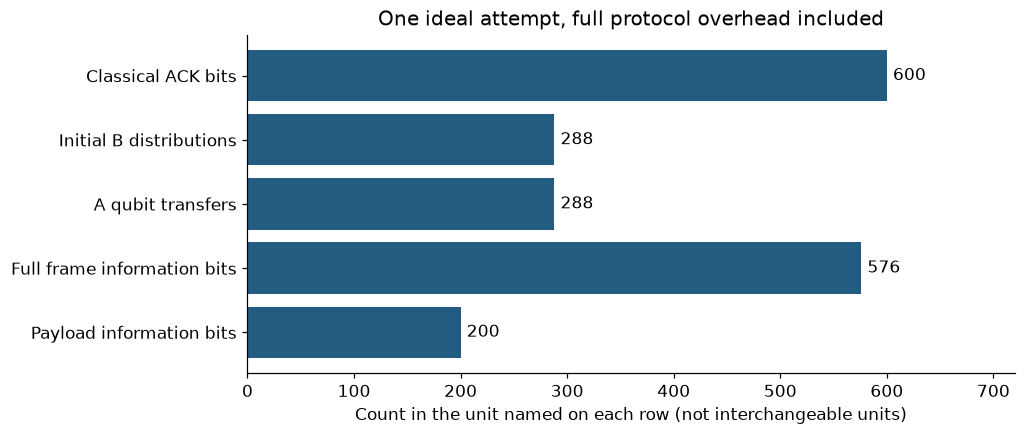

In [4]:
text = messages[0][2]
payload_bits = 8*len(text.encode())
frame_bits = 8*len(encode_message(text, 1))
costs = {'Payload information bits': payload_bits, 'Full frame information bits': frame_bits,
         'A qubit transfers': frame_bits//2, 'Initial B distributions': frame_bits//2, 'Classical ACK bits': ACK_SIZE*8}
fig, ax = plt.subplots(figsize=(9,4))
bars = ax.barh(list(costs), list(costs.values()), color=COLORS[0])
ax.bar_label(bars, padding=4)
ax.set_xlabel('Count in the unit named on each row (not interchangeable units)')
ax.set_xlim(0, max(costs.values())*1.2)
ax.set_title('One ideal attempt, full protocol overhead included')
save(fig, 'resource_accounting')
display(fig); plt.close(fig)


## 4. Penerimaan berbeda dari konfirmasi

Pada demonstrasi berikut, semua bit ACK sengaja dibalik. Penerima dapat
memperoleh teks, tetapi pengirim tidak menerima ACK valid. Pengiriman ulang
tidak membuat entri riwayat baru untuk sequence/fingerprint yang sama.
Ini kontrol kegagalan protokol, bukan hasil probabilistik yang disembunyikan.


In [5]:
lost_ack = ChatSession(seed=SEED, ack_noise=1.0, attempts=3)
for name in ('Bumi','Mars'):
    lost_ack.add_endpoint(name)
result = lost_ack.send('Bumi','Mars','Pesan diterima, ACK hilang')
assert result.received and not result.confirmed and len(lost_ack.history) == 1
display(pd.DataFrame(result.events))
print('Receiver accepted:', result.received, '| sender status:', result.status, '| unique deliveries:', len(lost_ack.history))


,attempt,accepted,fresh,ack_valid,error
0,1,True,True,False,None
1,2,True,False,False,None
2,3,True,False,False,None


Receiver accepted: True | sender status: UNCONFIRMED | unique deliveries: 1


## 5. Eksperimen terdefinisi: 100 pesan baru, dua arah

Pesan adalah fixture sintetik unik, bukan data latihan. Setiap kondisi memakai
seed root yang sama agar dapat direproduksi dalam backend/versi yang sama.
Ideal: noise nol, satu attempt. Berisik: depolarisasi A p=0.002, ACK bit error
q=0.0002, maksimum lima attempts. Kondisi lain tidak diubah. Tidak ada tuning
pada hasil uji dan tidak ada klaim evaluasi model bahasa.


In [6]:
benchmark_rows = []
for profile, p, q, limit in [('ideal',0.0,0.0,1), ('noisy',0.002,0.0002,5)]:
    chat = ChatSession(seed=SEED, noise=p, ack_noise=q, attempts=limit)
    for name in ('Bumi','Mars'):
        chat.add_endpoint(name)
    for i in range(100):
        sender, receiver = ('Bumi','Mars') if i % 2 == 0 else ('Mars','Bumi')
        truth = f'Uji ilmiah #{i}: {sender} ke {receiver} nilai {i*7919} 🌏'
        answer = chat.send(sender, receiver, truth)
        exact = answer.received and answer.received_text == truth
        assert not answer.received or exact
        assert answer.resources['sent_a_qubits'] == answer.resources['bell_pairs'] == answer.resources['distributed_b_qubits']
        assert answer.resources['classical_ack_bits'] == answer.attempts * 600
        benchmark_rows.append({'profile': profile, 'trial': i+1, 'exact_received': exact,
                               'confirmed': answer.confirmed, 'attempts': answer.attempts})
benchmark = pd.DataFrame(benchmark_rows)
summary = benchmark.groupby('profile').agg(trials=('trial','count'), exact_received=('exact_received','sum'),
                                          confirmed=('confirmed','sum'), mean_attempts=('attempts','mean'))
display(summary)


,trials,exact_received,confirmed,mean_attempts
profile,,,,
ideal,100,100,100,1.00
noisy,100,94,93,2.42


## 6. Ketidakpastian dan interpretasi

Wilson interval 95% di bawah mendeskripsikan proporsi konfirmasi pada sampel
simulasi ini. Interval bukan jaminan keandalan hardware atau bukti teorema.
Pesan memiliki panjang berbeda; probabilitas tanpa error per frame bergantung
L. Dengan asumsi independen, $s=(1-p)^{4L}(1-q)^{600}$ dan peluang konfirmasi
dalam R attempts adalah $1-(1-s)^R$, dengan mengabaikan tabrakan checksum.


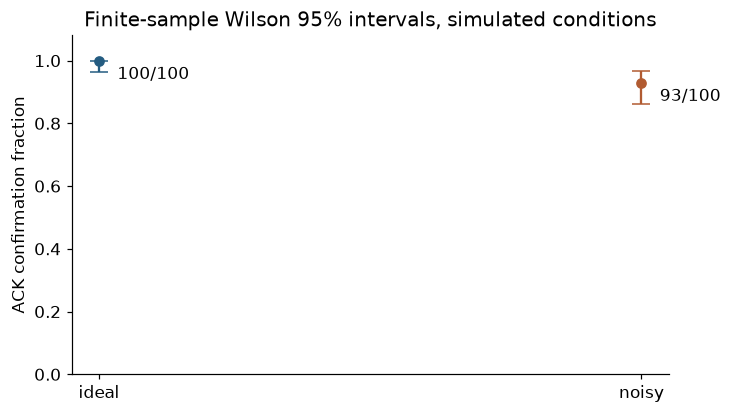

In [7]:
import math
def wilson(correct, total):
    z = 1.959963984540054
    p = correct/total
    center = (p+z*z/(2*total))/(1+z*z/total)
    half = z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/(1+z*z/total)
    return center-half, center+half
fig, ax = plt.subplots(figsize=(7,4))
for index, (profile, row) in enumerate(summary.iterrows()):
    rate = row['confirmed']/row['trials']
    low, high = wilson(int(row['confirmed']), int(row['trials']))
    ax.errorbar(index, rate, yerr=[[max(0, rate-low)],[max(0, high-rate)]], fmt='o', capsize=6, color=COLORS[index])
    ax.annotate(f'{int(row["confirmed"])}/{int(row["trials"])}', (index, rate), xytext=(12,-12), textcoords='offset points')
ax.set(xticks=[0,1], xticklabels=list(summary.index), ylim=(0,1.08), ylabel='ACK confirmation fraction',
       title='Finite-sample Wilson 95% intervals, simulated conditions')
save(fig, 'transport_confirmation')
display(fig); plt.close(fig)


## Batas eksperimen

Gate, storage, Bell preparation dan distribusi B ideal; noise hanya pada A
dan ACK. Tidak ada hardware, latency, erasure, autentikasi atau enkripsi.
Penerimaan yang belum terkonfirmasi harus tetap dilaporkan terpisah. Tidak
ada fixture rahasia pada decoder: truth hanya dipakai evaluator sesudah
pengukuran, decoding dan verifikasi. Data TCP riil pada mode dua terminal
tetap klasik dan tidak termasuk ledger model quantum di eksperimen in-process.


## Referensi primer dan cara mengutip

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX ada pada [docs/references.bib](../docs/references.bib), metadata software
pada [CITATION.cff](../CITATION.cff). Tidak ada DOI software atau klaim peer-review.
Notebook ini merupakan penjelasan dan verifikasi numerik protokol yang sudah ada.
